# DATA SCIENCE LIFECYCLE
# ASSIGNMENT ONE
# EUNYU SHADRACK
# S26M19/024


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 90


# QUESTION ONE - DATA QUALITY, MISSING VALUES, DUPLICATES AND OUTLIERS

In [1]:
raw = pd.read_csv('automobileEDA1.csv')
df = raw.copy()
print('Rows, columns:', df.shape)
df.head()

NameError: name 'pd' is not defined

# EXPLANATION
 The dataset has **201 rows and 29 columns**. 
 Each row is one car model/trim. 
 The preview shows engine, body and size measurements and the target column `price`. Note that `length` and `width` are already scaled (values around 0.8-1.0) while `wheel-base` and `height` are in inches.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non-null    st

**EXPLANATION ON OUTPUT:** 
`info()` shows the type of every column and how many values are non-missing. 19 columns are numeric (integer or decimal) and 10 are text (categorical). 
Every column has 201 values **except two**: `stroke` has 197 (4 missing) and `horsepower-binned` has 200 (1 missing). The next cells confirm this.

In [ ]:
# 1a. Missing values
missing = df.isna().sum()
print('Columns with missing values:')
print(missing[missing > 0])
print()
df[df.isna().any(axis=1)][['make', 'body-style', 'engine-type', 'num-of-cylinders', 'bore', 'stroke', 'horsepower', 'horsepower-binned']]

Columns with missing values:
stroke               4
horsepower-binned    1
dtype: int64



,make,body-style,engine-type,num-of-cylinders,bore,stroke,horsepower,horsepower-binned
46,jaguar,sedan,ohcv,twelve,3.540000,2.76,262.0,NaN
52,mazda,hatchback,rotor,two,3.329751,NaN,101.0,Low
53,mazda,hatchback,rotor,two,3.329751,NaN,101.0,Low
54,mazda,hatchback,rotor,two,3.329751,NaN,101.0,Low
55,mazda,hatchback,rotor,two,3.329751,NaN,135.0,Medium


**OUTPUT EXPLAINED - 
Missing values.** Only two columns have gaps, 5 missing cells in total:
- **`stroke` - 4 missing.** All four are Mazda **rotary (Wankel)** engines (`engine-type = rotor`). 
Rotary engines do not have a piston stroke in the normal sense, which is why the value is empty.
- **`horsepower-binned` - 1 missing.** This is the Jaguar with 262 hp, the most powerful car in the data, so its bin label was simply lost.

In [ ]:
# 1b. Duplicates
print('Exact duplicate rows            :', df.duplicated().sum())
print('Duplicates ignoring price column:', df.drop(columns='price').duplicated().sum())
print()
df[df.drop(columns='price').duplicated(keep=False)][['make', 'body-style', 'engine-size', 'horsepower', 'price']]

Exact duplicate rows            : 0
Duplicates ignoring price column: 7



,make,body-style,engine-size,horsepower,price
0,alfa-romero,convertible,130,111.0,13495
1,alfa-romero,convertible,130,111.0,16500
24,dodge,sedan,90,68.0,6692
25,dodge,sedan,90,68.0,7609
52,mazda,hatchback,70,101.0,10945
53,mazda,hatchback,70,101.0,11845
56,mazda,hatchback,122,84.0,8845
57,mazda,sedan,122,84.0,8495
58,mazda,hatchback,122,84.0,10595
59,mazda,sedan,122,84.0,10245


**OUTPUT EXPLAINED - DUPLICATES.
** There are **0 exact duplicate rows**. When `price` is ignored, 7 rows repeat another row (for example two Alfa-Romero convertibles, two Porsche hardtops). In each pair the specifications are identical but the **prices differ** (e.g. 13,495 vs 16,500), which means they are different trim levels or sales records rather than accidental copies.

In [ ]:
# OUTLIERS

#  : IQR rule (1.5 x IQR) on every numeric column
num_cols = [c for c in df.select_dtypes('number').columns if c not in ('diesel', 'gas', 'symboling')]

def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

outlier_table = pd.DataFrame({'n_outliers': {c: int(iqr_flags(df[c]).sum()) for c in num_cols}})
outlier_table['pct'] = (outlier_table['n_outliers'] / len(df) * 100).round(1)
outlier_table.sort_values('n_outliers', ascending=False)

,n_outliers,pct
compression-ratio,27,13.4
stroke,20,10.0
price,14,7.0
width,11,5.5
engine-size,10,5.0
normalized-losses,8,4.0
horsepower,5,2.5
wheel-base,3,1.5
highway-mpg,3,1.5
peak-rpm,2,1.0


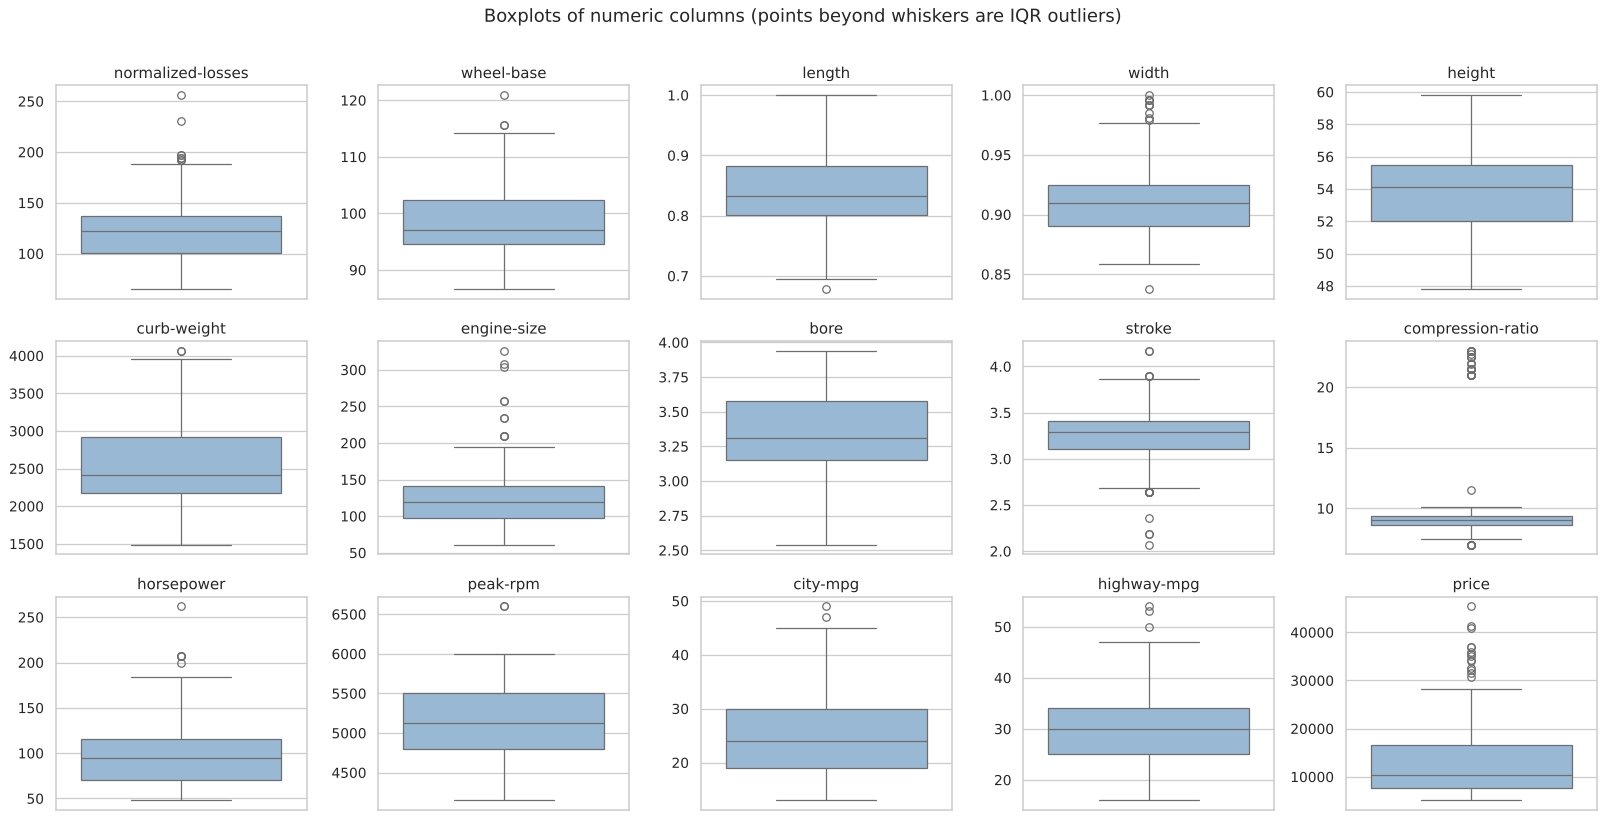

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color='#8fb8de')
    ax.set_title(c)
    ax.set_ylabel('')
plt.suptitle('Boxplots of numeric columns (points beyond whiskers are IQR outliers)', y=1.01)
plt.tight_layout()

**EXPLANNATION - OUTLIERS.
** The table counts values outside the usual range (1.5 x IQR rule) and the boxplots show them as dots beyond the whiskers. Most flagged values are **genuine**, not mistakes:
- **`compression-ratio` (27)** - diesel engines run at compression ratios of 21-23, petrol engines at 7-10, so diesels look like outliers but are correct.
- **`price` (14)**, **`engine-size` (10)**, **`horsepower` (5)**, **`curb-weight`** - luxury and performance cars (Mercedes-Benz, BMW, Jaguar, Porsche).
- **`stroke` (20)** and **`width` (11)** - the IQR range of these two is very narrow, so ordinary variation between engine designs is flagged.

Genuine extreme values carry real information about expensive cars, so they are **kept**. The only values that need a closer look are the odd `bore` / `stroke` readings in the next cell.

In [ ]:
# Are the bore / stroke outliers genuine or typing errors?
# Compare each car with sibling rows that share make, engine type, cylinders and engine size.
grp = ['make', 'engine-type', 'num-of-cylinders', 'engine-size']
for c in ['bore', 'stroke']:
    df[c + '_sibling_median'] = df.groupby(grp)[c].transform('median')
suspect = df[((df['bore'] - df['bore_sibling_median']).abs() > 0.5) |
             ((df['stroke'] - df['stroke_sibling_median']).abs() > 0.5)]
suspect[['make', 'body-style', 'engine-size', 'bore', 'bore_sibling_median', 'stroke', 'stroke_sibling_median', 'price']]

,make,body-style,engine-size,bore,bore_sibling_median,stroke,stroke_sibling_median,price
108,peugot,sedan,120,3.46,3.46,2.19,3.19,15580
110,peugot,wagon,120,3.46,3.46,2.19,3.19,16695
130,saab,hatchback,121,2.54,3.54,2.07,3.07,15040


In [ ]:
# ---- Handle the problems ----
# (a) Impossible bore/stroke values: replace with the median of sibling rows (same make/engine spec)
for c in ['bore', 'stroke']:
    bad = (df[c] - df[c + '_sibling_median']).abs() > 0.5
    df.loc[bad, c] = df.loc[bad, c + '_sibling_median']
df = df.drop(columns=['bore_sibling_median', 'stroke_sibling_median'])

# (b) Missing stroke (4 Mazda rotary cars): impute with the column median
stroke_median = df['stroke'].median()
df['stroke'] = df['stroke'].fillna(stroke_median)
print('stroke median used for imputation:', round(stroke_median, 2))

# (c) Missing horsepower-binned: every car with >= 156 hp is already 'High', and this Jaguar has 262 hp
print('Smallest horsepower already labelled High:', df.loc[df['horsepower-binned'] == 'High', 'horsepower'].min())
df['horsepower-binned'] = df['horsepower-binned'].fillna('High')

# (d) Price outliers are real expensive cars (Mercedes, BMW, Jaguar, Porsche) -> kept, not removed
print('Most expensive cars (kept):')
print(df.nlargest(5, 'price')[['make', 'body-style', 'engine-size', 'horsepower', 'price']].to_string())

# Verification
print()
print('Missing values left :', int(df.isna().sum().sum()))
print('Duplicate rows left :', int(df.duplicated().sum()))
print('Shape               :', df.shape)

stroke median used for imputation: 3.29
Smallest horsepower already labelled High: 156.0
Most expensive cars (kept):
              make   body-style  engine-size  horsepower  price
71   mercedes-benz      hardtop          304       184.0  45400
15             bmw        sedan          209       182.0  41315
70   mercedes-benz        sedan          308       184.0  40960
125        porsche  convertible          194       207.0  37028
16             bmw        sedan          209       182.0  36880

Missing values left : 0
Duplicate rows left : 0
Shape               : (201, 29)


**OUTPUT EXPLAINED - CLEANING RESULT.**
- 3 wrong bore/stroke entries replaced with sibling medians.
- 4 missing `stroke` values filled with the median **3.29**.
- 1 missing `horsepower-binned` set to `High`

Verification: **0 missing values, 0 duplicate rows, shape still 201 x 29.**

In [ ]:
# Sanity check on derived columns: city-L/100km should equal 235.2 / city-mpg
check = (df['city-L/100km'] - 235.215 / df['city-mpg']).abs()
print('Max gap between city-L/100km and 235.215/city-mpg:', round(check.max(), 2))
print('gas + diesel always equal to 1:', bool((df['gas'] + df['diesel'] == 1).all()))
print()
print('Values in the supplied file that look like an earlier mean-imputation:')
print('  normalized-losses == 122            :', int((df['normalized-losses'] == 122).sum()), 'rows')
print('  horsepower == 104.256, peak-rpm == 5125.37 :', int((df['horsepower'].round(3) == 104.256).sum()), 'rows (both Renault)')
print('  bore == 3.3298 (Mazda rotary)       :', int((df['bore'].round(4) == 3.3298).sum()), 'rows')
print()

df.to_csv('Eunyu.Data.csv', index=False)
print('Saved cleaned dataset -> Eunyu.Data.csv', df.shape)

Max gap between city-L/100km and 235.215/city-mpg: 0.02
gas + diesel always equal to 1: True

Values in the supplied file that look like an earlier mean-imputation:
  normalized-losses == 122            : 41 rows
  horsepower == 104.256, peak-rpm == 5125.37 : 2 rows (both Renault)
  bore == 3.3298 (Mazda rotary)       : 4 rows

Saved cleaned dataset -> Eunyu.Data.csv (201, 29)


---
## QUESTION TWO - 
PATTERNS, DESCRIPTIVE STATISTICS AND FREQUENCY COUNTS


In [ ]:
d = df.copy()
d['fuel-type'] = np.where(d['diesel'] == 1, 'diesel', 'gas')

continuous = ['normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size',
              'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg',
              'city-L/100km', 'price']
categorical = ['make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location',
               'engine-type', 'num-of-cylinders', 'fuel-system', 'horsepower-binned', 'symboling']

desc = d[continuous].describe().T
desc['median'] = d[continuous].median()
desc['skew'] = d[continuous].skew()
desc['kurtosis'] = d[continuous].kurt()
desc[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'skew', 'kurtosis']].round(2)

,count,mean,median,std,min,25%,75%,max,skew,kurtosis
normalized-losses,201.0,122.00,122.00,32.00,65.00,101.00,137.00,256.00,0.85,1.32
wheel-base,201.0,98.80,97.00,6.07,86.60,94.50,102.40,120.90,1.03,0.95
length,201.0,0.84,0.83,0.06,0.68,0.80,0.88,1.00,0.15,-0.07
width,201.0,0.92,0.91,0.03,0.84,0.89,0.92,1.00,0.88,0.68
height,201.0,53.77,54.10,2.45,47.80,52.00,55.50,59.80,0.03,-0.43
curb-weight,201.0,2555.67,2414.00,517.30,1488.00,2169.00,2926.00,4066.00,0.71,0.03
engine-size,201.0,126.88,120.00,41.55,61.00,98.00,141.00,326.00,1.98,5.50
bore,201.0,3.34,3.33,0.26,2.68,3.15,3.58,3.94,0.05,-1.03
stroke,201.0,3.27,3.29,0.29,2.36,3.15,3.41,4.17,-0.23,1.22
compression-ratio,201.0,10.16,9.00,4.00,7.00,8.60,9.40,23.00,2.58,5.07


**EXPLAINING OUTPUT - summary statistics for continuous variables.**
- **Price:** mean **13,207**, median **10,295**, standard deviation 7,947, range 5,118 to 45,400. The mean is well above the median and skewness is **1.81**, so price is **right-skewed**: most cars are cheap and a few luxury cars pull the average up. The middle half of cars cost between 7,775 and 16,500.
- **Strongly right-skewed predictors:** `compression-ratio` (skew 2.58), `engine-size` (1.98, with a few very large engines up to 326), `horsepower` (1.15), `wheel-base` (1.03).
- **Roughly symmetric:** `height`, `bore`, `peak-rpm` and `length` (skew between 0 and 0.15).
- `curb-weight` averages 2,556 lb and `horsepower` averages 103 hp; `city-mpg` averages 25 and `highway-mpg` 31.
- `normalized-losses` has mean exactly 122 because many missing values were filled with the mean before.

In [ ]:
# Frequency counts for every categorical variable
for c in categorical:
    vc = d[c].value_counts()
    out = pd.DataFrame({'count': vc, 'percent': (vc / len(d) * 100).round(1)})
    print(f'--- {c} ({d[c].nunique()} levels) ---')
    print(out.to_string())
    print()

--- make (22 levels) ---
               count  percent
make                         
toyota            32     15.9
nissan            18      9.0
mazda             17      8.5
honda             13      6.5
mitsubishi        13      6.5
subaru            12      6.0
volkswagen        12      6.0
peugot            11      5.5
volvo             11      5.5
dodge              9      4.5
bmw                8      4.0
mercedes-benz      8      4.0
plymouth           7      3.5
audi               6      3.0
saab               6      3.0
porsche            4      2.0
alfa-romero        3      1.5
chevrolet          3      1.5
jaguar             3      1.5
isuzu              2      1.0
renault            2      1.0
mercury            1      0.5

--- fuel-type (2 levels) ---
           count  percent
fuel-type                
gas          181     90.0
diesel        20     10.0

--- aspiration (2 levels) ---
            count  percent
aspiration                
std           165     82.1
turbo    

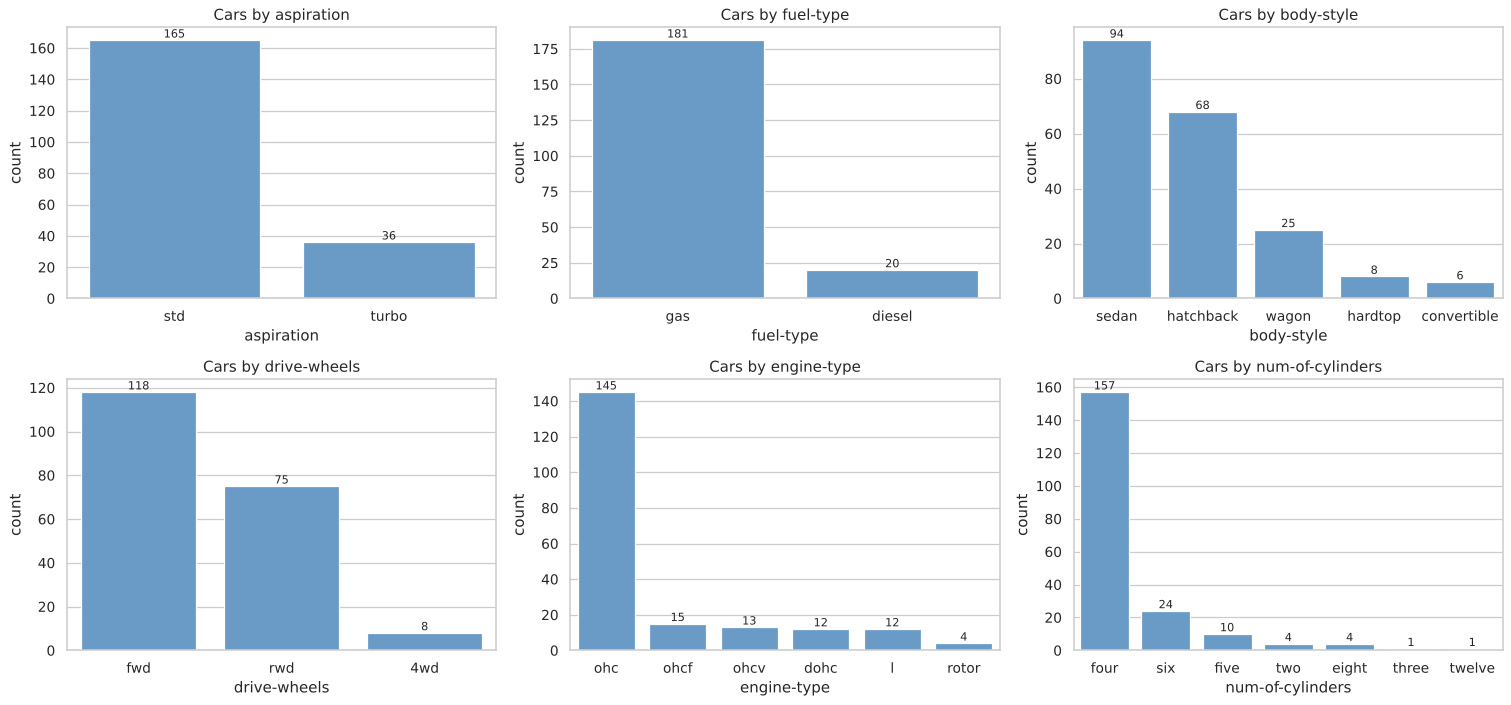

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.ravel(), ['aspiration', 'fuel-type', 'body-style', 'drive-wheels', 'engine-type', 'num-of-cylinders']):
    order = d[c].value_counts().index
    sns.countplot(data=d, x=c, order=order, ax=ax, color='#5b9bd5')
    ax.set_title(f'Cars by {c}')
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout()

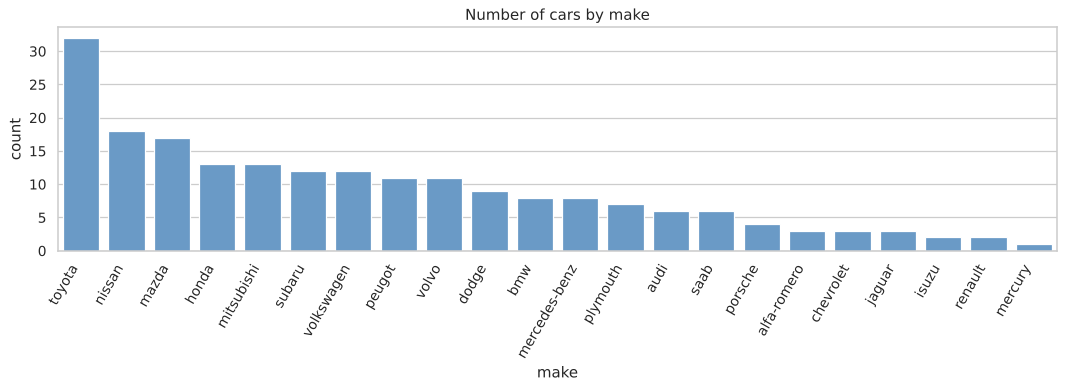

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.5))
order = d['make'].value_counts().index
sns.countplot(data=d, x='make', order=order, ax=ax, color='#5b9bd5')
ax.set_title('Number of cars by make')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()

# Each variable is dominated by one level (sedan, front-wheel drive, gas, standard aspiration, `ohc`, 4 cylinders), and the make chart shows a long tail of brands with few cars.

Price skewness: 1.81 | log(price) skewness: 0.68
Shapiro-Wilk on price     : p = 2.22e-15
Shapiro-Wilk on log(price): p = 1.43e-06
count      201.0
mean     13207.0
std       7947.0
min       5118.0
10%       6649.0
25%       7775.0
50%      10295.0
75%      16500.0
90%      22470.0
max      45400.0


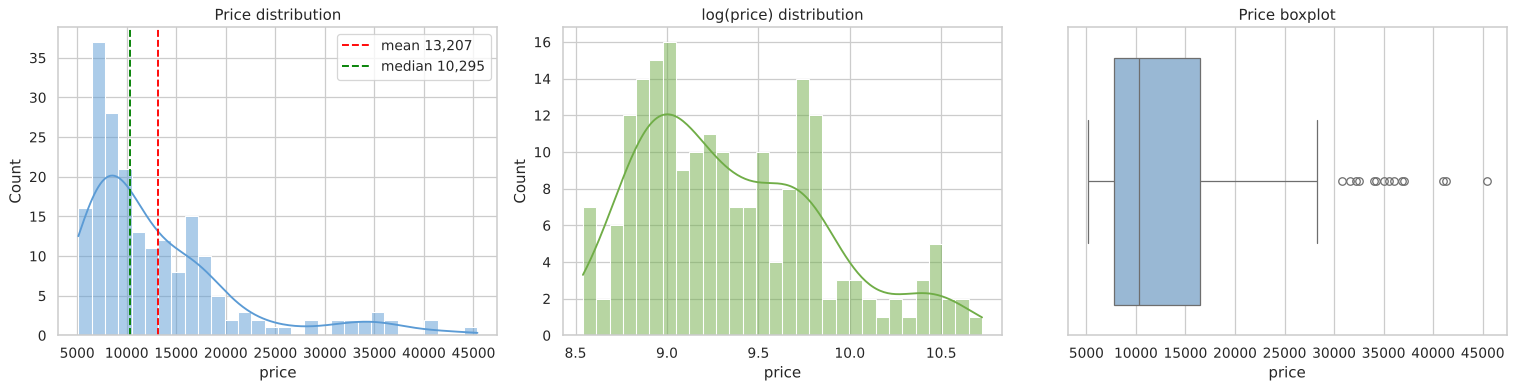

In [ ]:
# How is price distributed?
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(d['price'], kde=True, bins=30, ax=axes[0], color='#5b9bd5')
axes[0].axvline(d['price'].mean(), color='red', ls='--', label=f"mean {d['price'].mean():,.0f}")
axes[0].axvline(d['price'].median(), color='green', ls='--', label=f"median {d['price'].median():,.0f}")
axes[0].legend(); axes[0].set_title('Price distribution')
sns.histplot(np.log(d['price']), kde=True, bins=30, ax=axes[1], color='#70ad47')
axes[1].set_title('log(price) distribution')
sns.boxplot(x=d['price'], ax=axes[2], color='#8fb8de'); axes[2].set_title('Price boxplot')
plt.tight_layout()
print('Price skewness:', round(d['price'].skew(), 2), '| log(price) skewness:', round(np.log(d['price']).skew(), 2))
print('Shapiro-Wilk on price     : p =', f"{stats.shapiro(d['price']).pvalue:.2e}")
print('Shapiro-Wilk on log(price): p =', f"{stats.shapiro(np.log(d['price'])).pvalue:.2e}")
print(d['price'].describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())

## EXPLANNATION
- The histogram has a long **right tail**: the mean (red line, 13,207) sits to the right of the median (green line, 10,295). The boxplot confirms the high-price points.
- Taking the logarithm reduces the skew from **1.81 to 0.68**, so the log scale is much more symmetric. This matters if a linear model is used later.
- The Shapiro-Wilk test rejects normality for both price (p about 2e-15) and log(price) (p about 1e-6), so price is **not normally distributed**; I therefore also report rank-based (Spearman, Kruskal-Wallis) results later.
- Percentiles: 10% of cars cost under 6,649, half under 10,295 and 90% under 22,470. Only the top 10% are priced above 22,470.

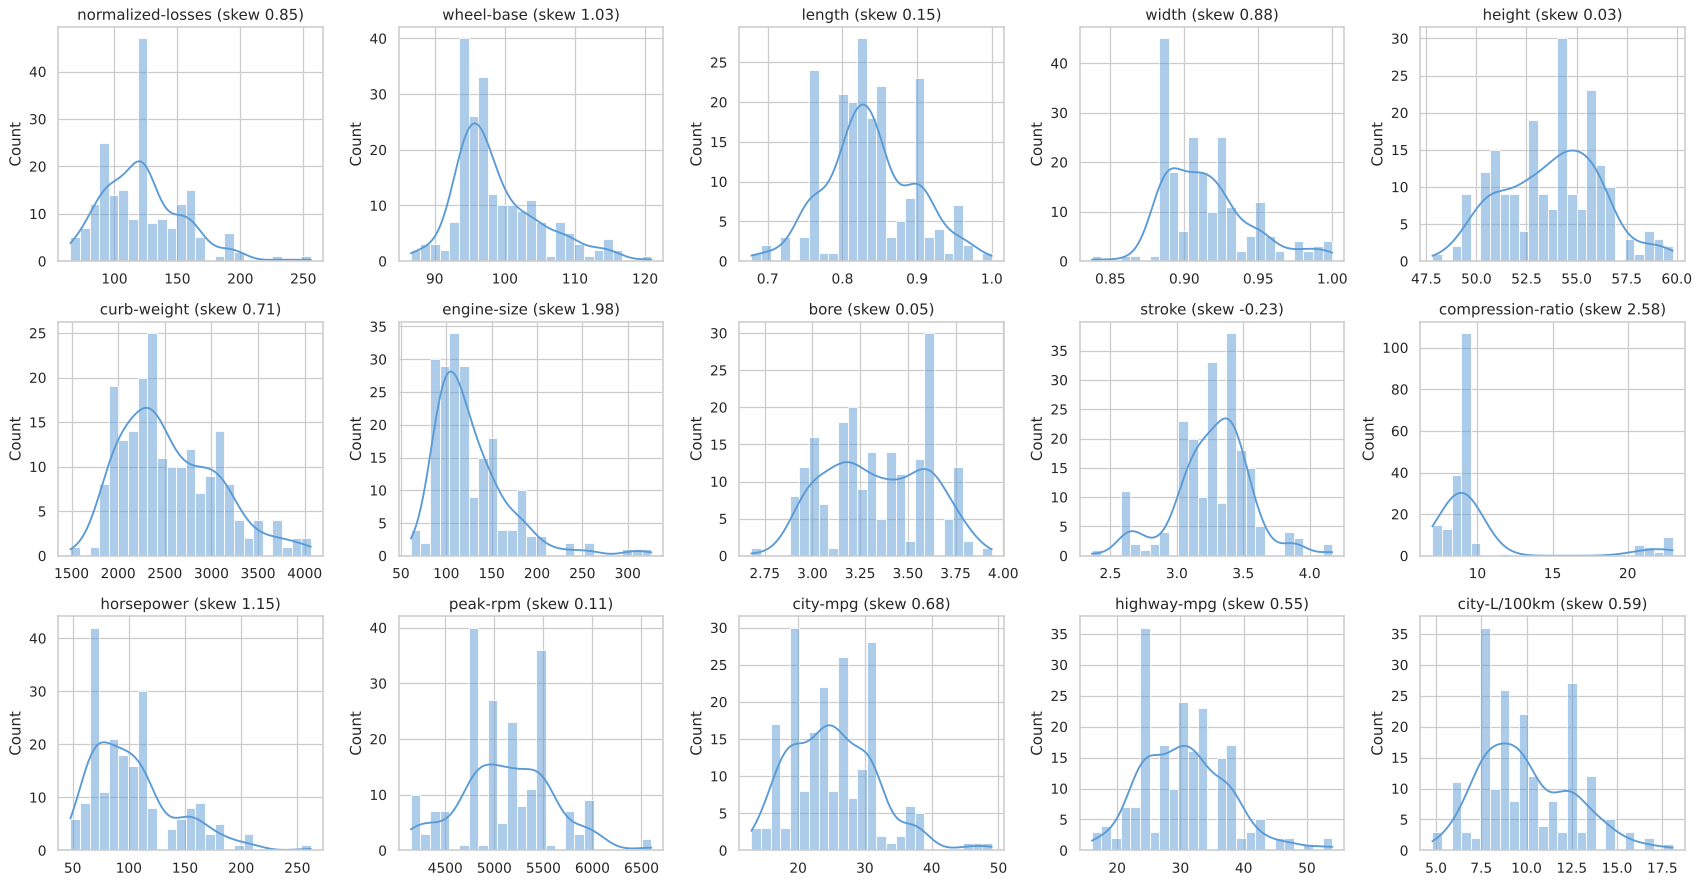

In [ ]:
# Distributions of the other continuous variables
others = [c for c in continuous if c != 'price']
fig, axes = plt.subplots(3, 5, figsize=(19, 10))
for ax, c in zip(axes.ravel(), others):
    sns.histplot(d[c], kde=True, ax=ax, color='#5b9bd5', bins=25)
    ax.set_title(f"{c} (skew {d[c].skew():.2f})")
    ax.set_xlabel('')
plt.tight_layout()

**EXPLANNATION:** the histograms match the skewness numbers. `engine-size`, `compression-ratio` and `horsepower` have long right tails, and `compression-ratio` has **two separate clusters** (petrol cars at 7-10, diesel at about 21-23). `height`, `bore`, `peak-rpm` and `length` look close to symmetric. `city-mpg` and `highway-mpg` are mildly right-skewed because a few small economy cars reach 45-54 mpg.

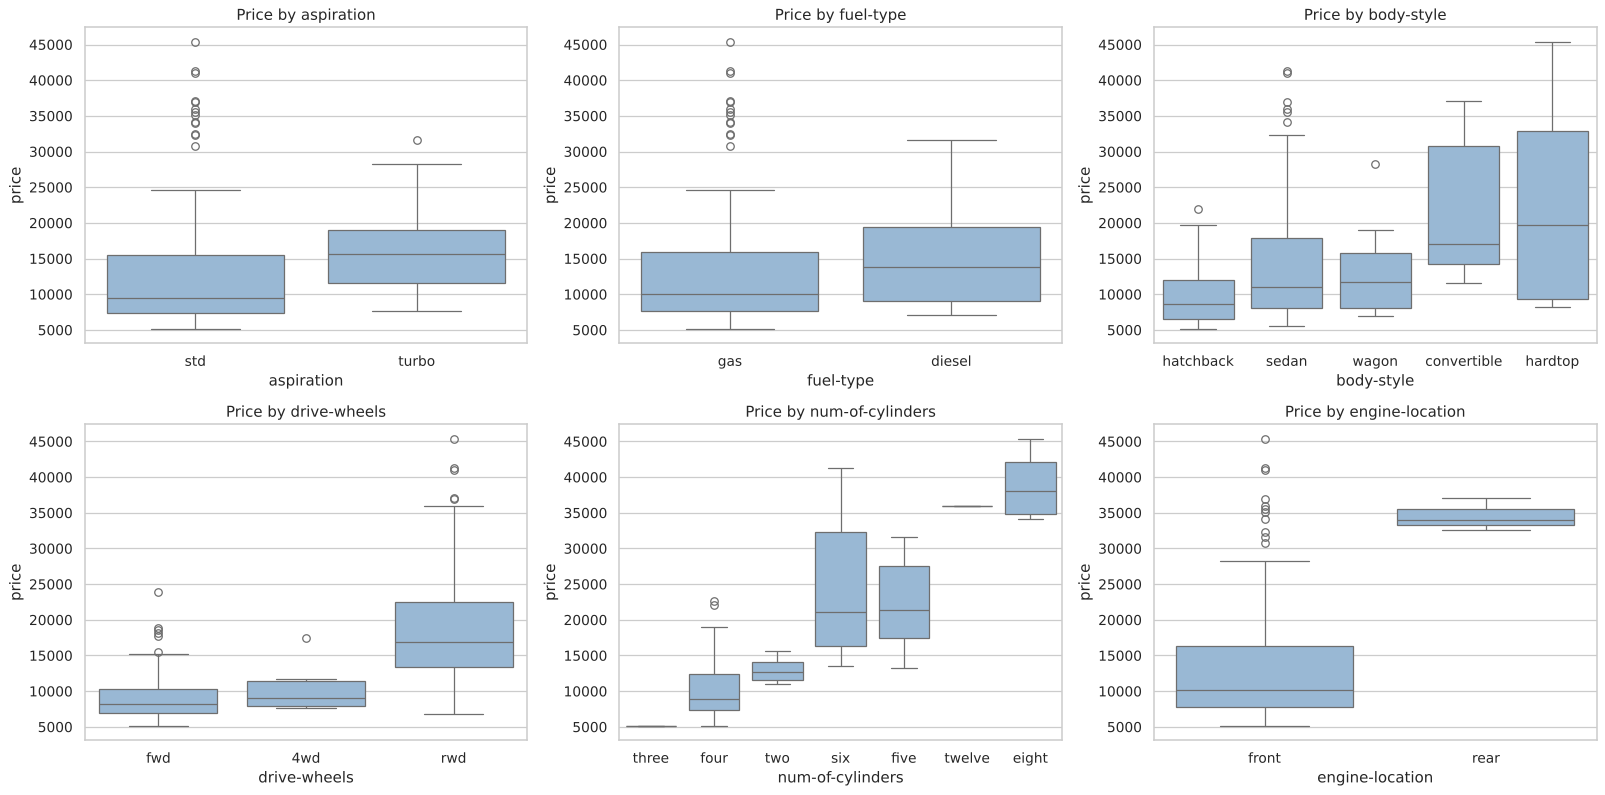

In [ ]:
# Price by categorical variables: how do the patterns look?
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), ['aspiration', 'fuel-type', 'body-style', 'drive-wheels', 'num-of-cylinders', 'engine-location']):
    order = d.groupby(c)['price'].median().sort_values().index
    sns.boxplot(data=d, x=c, y='price', order=order, ax=ax, color='#8fb8de')
    ax.set_title(f'Price by {c}')
plt.tight_layout()

## EXPLANATION
- patterns of price across categories (boxplots, ordered from lowest to highest median):**
- **Drive wheels:** rear-wheel drive cars are clearly the most expensive (median 16,900) compared with front-wheel (8,192) and four-wheel (9,006).
- **Body style:** hardtops and convertibles are priced highest, hatchbacks lowest.
- **Cylinders:** price rises steeply with cylinders - 8 and 12 cylinder cars are the most expensive, while 4-cylinder cars are the cheapest of the common types.
- **Aspiration:** turbo cars have a higher median price (15,686 vs 9,538 for standard).
- **Fuel type:** diesel median (13,852) is higher than gas (9,989), but the spread overlaps a lot (tested later).
- **Engine location:** rear-engine cars are all Porsches and all expensive.

**Summary of patterns in Q2:** price is right-skewed; bigger, more powerful, heavier cars cost more; rear-wheel drive, turbo and many-cylinder cars cost more; economy hatchbacks are cheapest.

---
## QUESTION THREE AVERAGE PRICE BY GROUP

In [ ]:
def group_summary(col):
    g = d.groupby(col)['price'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(0)
    return g.sort_values('mean', ascending=False)

print('Average price by drive-wheels'); print(group_summary('drive-wheels').to_string()); print()
print('Average price by body-style');   print(group_summary('body-style').to_string())

Average price by drive-wheels
              count     mean   median     std   min    max
drive-wheels                                              
rwd              75  19758.0  16900.0  9083.0  6785  45400
4wd               8  10241.0   9006.0  3288.0  7603  17450
fwd             118   9245.0   8192.0  3346.0  5118  23875

Average price by body-style
             count     mean   median      std    min    max
body-style                                                 
hardtop          8  22208.0  19688.0  14556.0   8249  45400
convertible      6  21890.0  17084.0  11188.0  11595  37028
sedan           94  14460.0  11078.0   8523.0   5499  41315
wagon           25  12372.0  11694.0   5121.0   6918  28248
hatchback       68   9957.0   8672.0   4149.0   5118  22018


** average price by group.**

| Drive-wheels | Cars | Mean price | Median |
|---|---|---|---|
| rwd | 75 | **19,758** | 16,900 |
| 4wd | 8 | 10,241 | 9,006 |
| fwd | 118 | **9,245** | 8,192 |

| Body style | Cars | Mean price | Median |
|---|---|---|---|
| hardtop | 8 | **22,208** | 19,688 |
| convertible | 6 | 21,890 | 17,084 |
| sedan | 94 | 14,460 | 11,078 |
| wagon | 25 | 12,372 | 11,694 |
| hatchback | 68 | **9,957** | 8,672 |

For drive-wheels the **highest average price is rwd (19,758)** and the **lowest is fwd (9,245)**. 
For body style the **highest is hardtop (22,208)** and the **lowest is hatchback (9,957)**. 
Rear-wheel drive cars cost more than twice as much as front-wheel drive cars on average.
Hardtop and convertible have only 8 and 6 cars, so their averages are less certain (the standard deviation is 14,556 and 11,188).

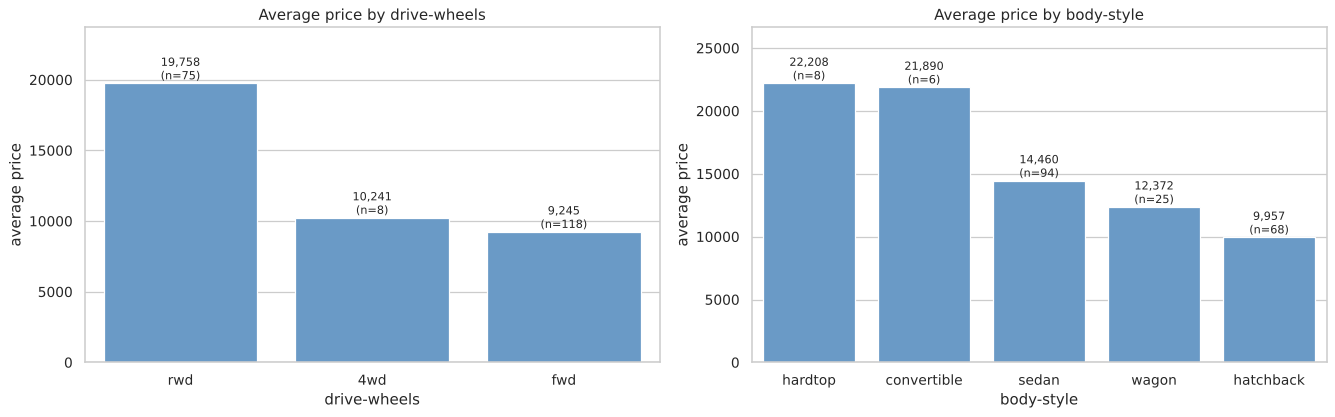

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, c in zip(axes, ['drive-wheels', 'body-style']):
    g = group_summary(c)
    sns.barplot(x=g.index, y=g['mean'], ax=ax, color='#5b9bd5')
    ax.set_title(f'Average price by {c}'); ax.set_ylabel('average price')
    for i, (m, n) in enumerate(zip(g['mean'], g['count'])):
        ax.text(i, m, f'{m:,.0f}\n(n={int(n)})', ha='center', va='bottom', fontsize=9)
    ax.set_ylim(0, g['mean'].max() * 1.2)
plt.tight_layout()

The bar charts show the same averages, with the number of cars (n) above each bar. 
The rwd bar is about double the fwd and 4wd bars; hardtop and convertible stand well above sedan, wagon and hatchback.

In [ ]:
# Combined groups: drive-wheels x body-style
combo = d.groupby(['drive-wheels', 'body-style'])['price'].agg(['count', 'mean']).round(0).reset_index()
pivot_mean = d.pivot_table(index='drive-wheels', columns='body-style', values='price', aggfunc='mean').round(0)
pivot_n = d.pivot_table(index='drive-wheels', columns='body-style', values='price', aggfunc='count').fillna(0).astype(int)
print('Average price'); print(pivot_mean.to_string()); print(); print('Number of cars'); print(pivot_n.to_string())

hi = combo[combo['count'] >= 3].sort_values('mean')
print('\nGroups with at least 3 cars -> lowest and highest average price:')
print('LOWEST :', hi.iloc[0].to_dict())
print('HIGHEST:', hi.iloc[-1].to_dict())
print('\nAll groups (any size) -> lowest/highest:')
print('LOWEST :', combo.sort_values('mean').iloc[0].to_dict())
print('HIGHEST:', combo.sort_values('mean').iloc[-1].to_dict())

Average price
body-style    convertible  hardtop  hatchback    sedan    wagon
drive-wheels                                                   
4wd                   NaN      NaN     7603.0  12647.0   9096.0
fwd               11595.0   8249.0     8396.0   9812.0   9997.0
rwd               23950.0  24203.0    14338.0  21712.0  16994.0

Number of cars
body-style    convertible  hardtop  hatchback  sedan  wagon
drive-wheels                                               
4wd                     0        0          1      3      4
fwd                     1        1         49     55     12
rwd                     5        7         18     36      9

Groups with at least 3 cars -> lowest and highest average price:
LOWEST : {'drive-wheels': 'fwd', 'body-style': 'hatchback', 'count': 49, 'mean': 8396.0}
HIGHEST: {'drive-wheels': 'rwd', 'body-style': 'hardtop', 'count': 7, 'mean': 24203.0}

All groups (any size) -> lowest/highest:
LOWEST : {'drive-wheels': '4wd', 'body-style': 'hatchback', 'count

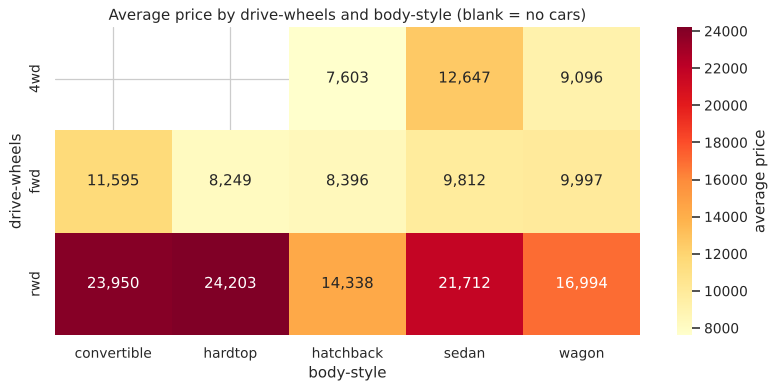

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(pivot_mean, annot=True, fmt=',.0f', cmap='YlOrRd', ax=ax, cbar_kws={'label': 'average price'})
ax.set_title('Average price by drive-wheels and body-style (blank = no cars)')
plt.tight_layout()

**EXPLANATION.** 
The heatmap and tables give the average price of each drive-wheels x body-style group:
- **Highest average price: rwd hardtop - 24,203** (7 cars), closely followed by rwd convertible (23,950, 5 cars) and rwd sedan (21,712, 36 cars).
- **Lowest average price: fwd hatchback - 8,396** (49 cars) when only groups with at least 3 cars are considered. The raw lowest is 4wd hatchback at 7,603, but that is a **single car**, so it is not a reliable group average.
- **Front-wheel drive stays cheap whatever the body** (8,249 to 11,595), while **rear-wheel drive is expensive whatever the body** (14,338 to 24,203). Drive-wheels therefore matters more than body style.

In [ ]:
# Statistical tests: do group means really differ?
for c in ['drive-wheels', 'body-style']:
    groups = [g['price'].values for _, g in d.groupby(c) if len(g) >= 3]
    F, p = stats.f_oneway(*groups)
    H, pk = stats.kruskal(*groups)
    print(f'{c:13s}: ANOVA F = {F:6.2f}, p = {p:.2e} | Kruskal-Wallis H = {H:6.2f}, p = {pk:.2e}')

# Pairwise comparison of drive-wheels (Tukey HSD)
dw = [d.loc[d['drive-wheels'] == k, 'price'] for k in ['fwd', 'rwd', '4wd']]
print()
print(stats.tukey_hsd(*dw))

drive-wheels : ANOVA F =  67.95, p = 3.39e-23 | Kruskal-Wallis H =  93.19, p = 5.81e-21
body-style   : ANOVA F =   9.13, p = 8.78e-07 | Kruskal-Wallis H =  25.02, p = 4.98e-05

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1) -10512.834     0.000-12657.692 -8367.975
 (0 - 2)   -996.220     0.897 -6302.509  4310.068
 (1 - 0)  10512.834     0.000  8367.975 12657.692
 (1 - 2)   9516.613     0.000  4114.608 14918.618
 (2 - 0)    996.220     0.897 -4310.068  6302.509
 (2 - 1)  -9516.613     0.000-14918.618 -4114.608



---
## QUESSTION 4, EFFECT OF THE INDEPENDENT ATTRIBUTES ON PRICE
**(a)** continuous variables vs price, **(b)** categorical variables vs price, **(c)** two categorical variables together.

In [ ]:
# 4a. Continuous variables vs price
cont_x = [c for c in continuous if c != 'price']
rows = []
for c in cont_x:
    r, p = stats.pearsonr(d[c], d['price'])
    rho, _ = stats.spearmanr(d[c], d['price'])
    rows.append((c, r, rho, p))
corr_table = pd.DataFrame(rows, columns=['variable', 'pearson_r', 'spearman_rho', 'p_value']).set_index('variable')
corr_table['abs_r'] = corr_table['pearson_r'].abs()
corr_table = corr_table.sort_values('abs_r', ascending=False)
corr_table.round(3)

,pearson_r,spearman_rho,p_value,abs_r
variable,,,,
engine-size,0.872,0.828,0.000,0.872
curb-weight,0.834,0.914,0.000,0.834
horsepower,0.810,0.849,0.000,0.810
city-L/100km,0.790,0.831,0.000,0.790
width,0.751,0.812,0.000,0.751
highway-mpg,-0.705,-0.827,0.000,0.705
length,0.691,0.810,0.000,0.691
city-mpg,-0.687,-0.831,0.000,0.687
wheel-base,0.585,0.682,0.000,0.585


**continuous variable with price.** Pearson r measures a straight-line relationship (-1 to +1); Spearman rho measures any steadily rising/falling relationship.
- **Strong positive:** `engine-size` (r = **0.87**), `curb-weight` (**0.83**), `horsepower` (**0.81**), `city-L/100km` (0.79, fuel consumption), `width` (0.75), `length` (0.69).
- **Strong negative:** `highway-mpg` (**-0.71**) and `city-mpg` (-0.69): more fuel-efficient cars are cheaper.
- **Moderate:** `wheel-base` (0.59) and `bore` (0.56).
- **No meaningful effect:** `height` (0.14), `normalized-losses` (0.13), `stroke` (0.11), `peak-rpm` (-0.10) and `compression-ratio` (0.07); all have p-values above 0.05, so they are **not statistically significant**.
- Spearman for `curb-weight` (0.91) and the mpg variables (about -0.83) is higher than Pearson, meaning these relationships rise steadily but are slightly curved.

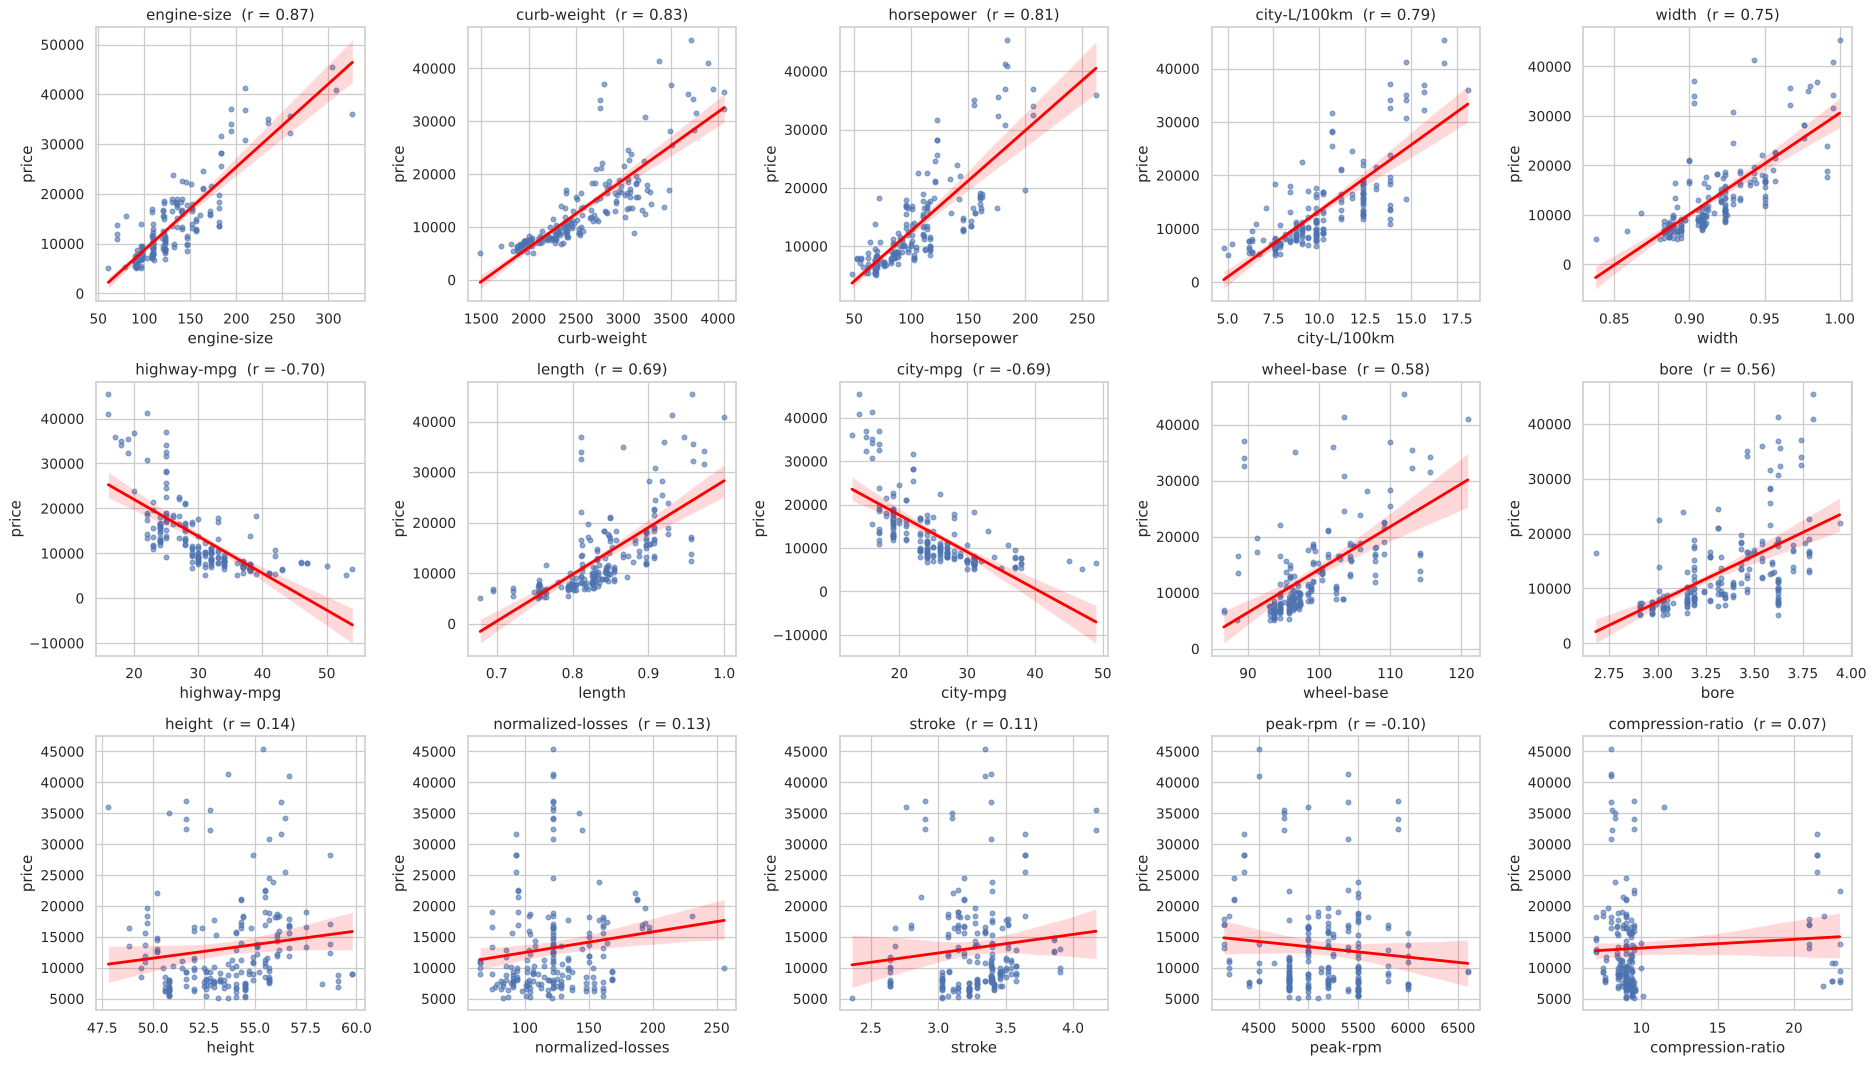

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(21, 12))
for ax, c in zip(axes.ravel(), corr_table.index):
    sns.regplot(data=d, x=c, y='price', ax=ax, scatter_kws={'s': 14, 'alpha': .6}, line_kws={'color': 'red'})
    ax.set_title(f"{c}  (r = {corr_table.loc[c, 'pearson_r']:.2f})")
    ax.set_ylabel('price')
plt.tight_layout()

**EXPANNATION:** each scatter plot shows price against one variable with a fitted line. The upward cloud for engine size, curb weight, horsepower, width and length confirms the positive relationships, and the downward cloud for the mpg variables confirms the negative ones. The panels for `height`, `stroke`, `peak-rpm`, `compression-ratio` and `normalized-losses` are shapeless clouds with a flat line, so those variables do not help explain price. The spread widens at high values, meaning expensive cars are harder to predict.

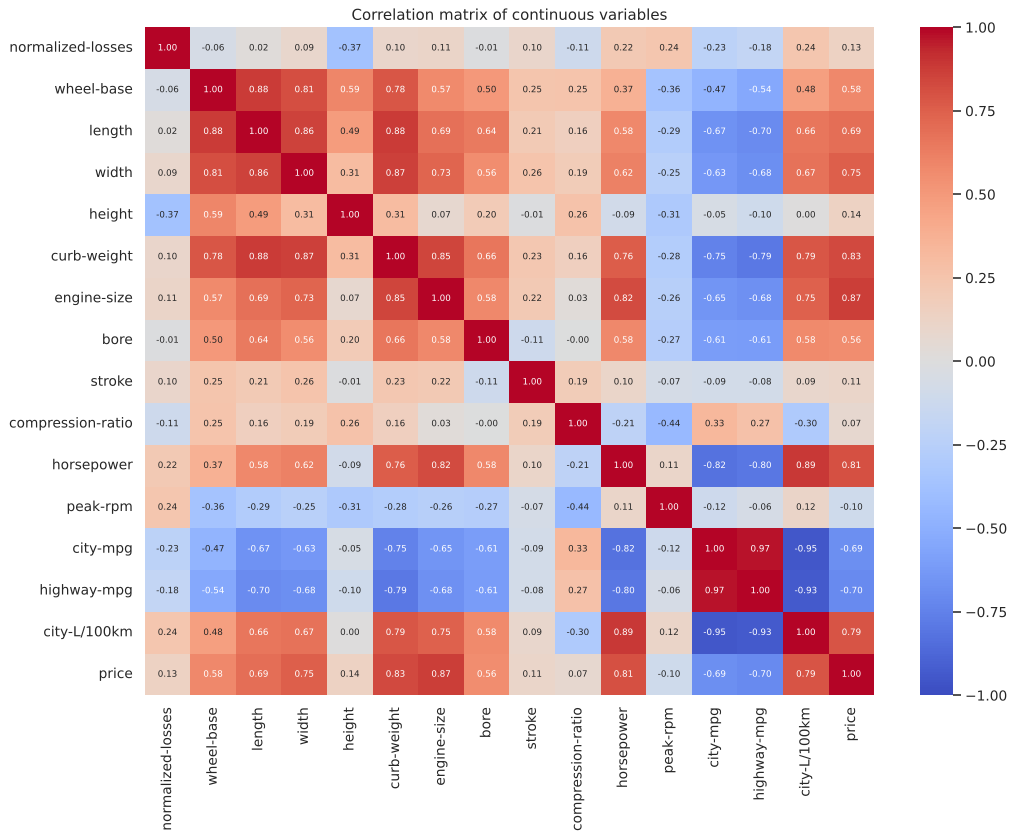

In [ ]:
fig, ax = plt.subplots(figsize=(12, 9.5))
cm = d[continuous].corr()
sns.heatmap(cm, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 7})
ax.set_title('Correlation matrix of continuous variables')
plt.tight_layout()

**EXPLANNATION - correlation matrix.** Red means positive correlation, blue negative. The price row/column repeats the table above, and the matrix also shows that the **predictors are strongly correlated with each other** (e.g. engine-size and curb-weight 0.85, engine-size and horsepower 0.82, city-mpg and highway-mpg 0.97, city-mpg and city-L/100km -0.95, wheel-base and length 0.88). They largely describe the same thing: how big and powerful the car is. This is **multicollinearity**, so I should not count them as independent pieces of evidence, and the fuel-economy columns can be reduced to one in a model.

In [ ]:
# 4b. CATEGORICAL VARIABBLES AND PRICE: ANOVA F-test and eta-squared (share of price variance explained)
rows = []
for c in categorical:
    groups = [g['price'].values for _, g in d.groupby(c)]
    F, p = stats.f_oneway(*[g for g in groups if len(g) > 1])
    ss_between = sum(len(g) * (g.mean() - d['price'].mean()) ** 2 for g in groups)
    ss_total = ((d['price'] - d['price'].mean()) ** 2).sum()
    rows.append((c, d[c].nunique(), F, p, ss_between / ss_total))
cat_table = pd.DataFrame(rows, columns=['variable', 'levels', 'F', 'p_value', 'eta_squared']).set_index('variable')
cat_table.sort_values('eta_squared', ascending=False).round(4)

,levels,F,p_value,eta_squared
variable,,,,
make,22,34.8558,0.0000,0.7959
num-of-cylinders,7,76.3470,0.0000,0.6295
horsepower-binned,3,108.5048,0.0000,0.5229
drive-wheels,3,67.9541,0.0000,0.4070
fuel-system,8,21.0118,0.0000,0.3527
engine-type,6,9.8451,0.0000,0.2016
body-style,5,9.1288,0.0000,0.1570
symboling,6,6.8480,0.0000,0.1494
engine-location,2,24.4956,0.0000,0.1096


**Categorical variables vs price.** For each categorical variable the ANOVA F-test checks whether average price differs between its levels, and **eta-squared** is the share of the total variation in price explained by that variable alone (0 = none, 1 = all).
- **Strong:** `make` (0.80), `num-of-cylinders` (0.63), `horsepower-binned` (0.52), `drive-wheels` (0.41), `fuel-system` (0.35).
- **Moderate/weak:** `engine-type` (0.20), `body-style` (0.16), `symboling` (0.15), `engine-location` (0.11).
- **Very weak:** `aspiration` (0.03, p = 0.011).
- **No effect:** `fuel-type` (0.012, p = 0.119) and `num-of-doors` (0.002, p = 0.55) are not significant.

Caution: `make` has 22 levels, many with only a few cars, which inflates its eta-squared, and brand is closely tied to engine size and power. `fuel-system` is mostly separating diesel (`idi`) from the engine-injection types.

---
## Question 5 - Main variables affecting price and recommendation

In [ ]:
from sklearn.feature_selection import f_regression, mutual_info_regression, RFECV
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline

y = d['price']
num_feats = [c for c in continuous if c != 'price']           # 15 continuous predictors
cat_feats = [c for c in categorical if c != 'horsepower-binned']  # binned hp is just horsepower in 3 groups
X_num = d[num_feats]
X_all = pd.get_dummies(d[num_feats + cat_feats].astype({'symboling': str}), drop_first=False, dtype=float)
print('Predictors:', len(num_feats), 'continuous +', len(cat_feats), 'categorical ->', X_all.shape[1], 'columns after one-hot encoding')

Predictors: 15 continuous + 11 categorical -> 80 columns after one-hot encoding


**Output explained:** the candidate predictors are 15 continuous and 11 categorical variables, which become **80 columns** after one-hot encoding (each category turned into a 0/1 column so the algorithms can use it).

In [ ]:
# Method 1 - Filter: F-test (SelectKBest f_regression) and mutual information on continuous variables
F, pF = f_regression(X_num, y)
mi = mutual_info_regression(X_num, y, random_state=42)
filt = pd.DataFrame({'F_score': F, 'mutual_info': mi}, index=num_feats)

# Method 2 - Embedded: Random Forest importance (summed over one-hot columns back to the original variable)
rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1).fit(X_all, y)
imp = pd.Series(rf.feature_importances_, index=X_all.columns)
base = {c: c for c in num_feats}
def parent(col):
    for c in cat_feats:
        if col.startswith(c + '_'):
            return c
    return col
rf_imp = imp.groupby(parent).sum()

# Method 3 - Wrapper: recursive feature elimination with cross-validation (Ridge on standardised continuous variables)
Xs = pd.DataFrame(StandardScaler().fit_transform(X_num), columns=num_feats)
rfecv = RFECV(Ridge(alpha=1.0), step=1, cv=KFold(5, shuffle=True, random_state=42), scoring='r2').fit(Xs, y)
filt['RFECV_rank'] = rfecv.ranking_
filt['RF_importance'] = rf_imp.reindex(num_feats)
filt = filt.sort_values('F_score', ascending=False)
print('RFECV kept', rfecv.n_features_, 'continuous variables:', list(Xs.columns[rfecv.support_]))
filt.round(3)

RFECV kept 11 continuous variables: ['wheel-base', 'length', 'width', 'curb-weight', 'engine-size', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'highway-mpg', 'city-L/100km']


,F_score,mutual_info,RFECV_rank,RF_importance
engine-size,633.527,0.840,1,0.636
curb-weight,456.139,0.892,1,0.210
horsepower,378.500,0.859,1,0.015
city-L/100km,330.168,0.773,1,0.005
width,257.841,0.670,1,0.014
highway-mpg,196.305,0.872,1,0.049
length,181.474,0.575,1,0.006
city-mpg,177.452,0.741,3,0.003
wheel-base,103.342,0.586,1,0.009
bore,90.436,0.460,4,0.004


**Output explained - continuous variables.**
- **F-test:** `engine-size` (634), `curb-weight` (456), `horsepower` (379), `city-L/100km` (330) and `width` (258) score highest; `height`, `normalized-losses`, `stroke`, `peak-rpm` and `compression-ratio` score very low (F below 4).
- **Mutual information:** the best are `curb-weight` (0.89), `highway-mpg` (0.87), `horsepower` (0.86) and `engine-size` (0.84); `normalized-losses` and `peak-rpm` are the weakest.
- **Random Forest importance:** `engine-size` alone takes **63.6%** and `curb-weight` **21.0%** of the total, so these two dominate.
- **RFECV** kept 11 variables and only eliminated the weakest four: `height`, `normalized-losses`, `city-mpg` and `bore`. It is not very strict because a few weak variables add a tiny gain, and `city-mpg` is probably dropped because `highway-mpg` and `city-L/100km` already carry almost the same information.

In [ ]:
# Categorical variables: ANOVA eta-squared (from 4b) and Random Forest importance
cat_rank = pd.DataFrame({'eta_squared': cat_table.loc[cat_feats, 'eta_squared'],
                         'RF_importance': rf_imp.reindex(cat_feats)}).sort_values('eta_squared', ascending=False)
cat_rank.round(3)

,eta_squared,RF_importance
make,0.796,0.009
num-of-cylinders,0.630,0.002
drive-wheels,0.407,0.001
fuel-system,0.353,0.002
engine-type,0.202,0.002
body-style,0.157,0.003
symboling,0.149,0.002
engine-location,0.110,0.000
aspiration,0.032,0.002
fuel-type,0.012,0.001


**Output explained - categorical variables.** Ranked by eta-squared: `make` (0.80), `num-of-cylinders` (0.63), `drive-wheels` (0.41), `fuel-system` (0.35), then `engine-type`, `body-style`, `symboling`, `engine-location`; `aspiration`, `fuel-type` and `num-of-doors` are near zero. The Random Forest importances for categorical variables are tiny (below 0.01) because the forest already gets the same information from `engine-size` and `curb-weight`, and each category is split across several 0/1 columns. This means categorical variables mostly **add detail on top of** the size/power variables rather than replace them.

Continuous variables, best to worst:
                   F-test  Mutual info  RF importance  avg_rank
curb-weight           2.0          1.0            2.0       1.7
engine-size           1.0          4.0            1.0       2.0
horsepower            3.0          3.0            4.0       3.3
highway-mpg           6.0          2.0            3.0       3.7
width                 5.0          7.0            5.0       5.7
city-L/100km          4.0          5.0           10.0       6.3
wheel-base            9.0          8.0            6.0       7.7
length                7.0          9.0            8.0       8.0
city-mpg              8.0          6.0           14.0       9.3
bore                 10.0         10.0           11.0      10.3
normalized-losses    12.0         14.0            7.0      11.0
height               11.0         12.0           12.0      11.7
compression-ratio    15.0         13.0            9.0      12.3
stroke               13.0         11.0           15.0      13.0
pea

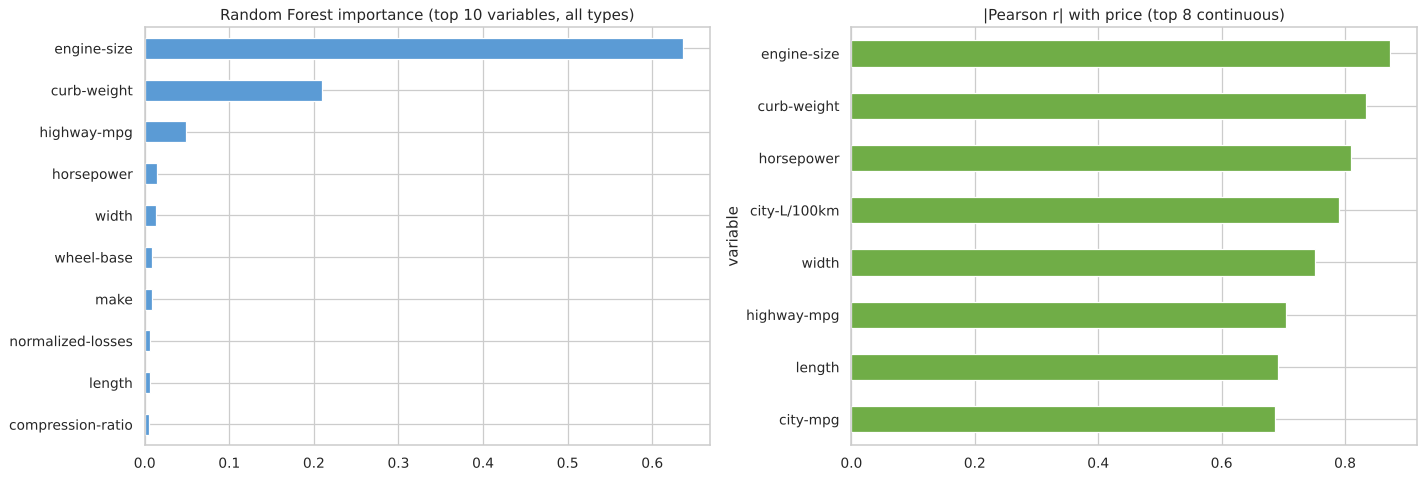

In [ ]:
# Consensus ranking: average rank across the methods
ranks = pd.DataFrame(index=num_feats)
ranks['F-test'] = filt['F_score'].rank(ascending=False)
ranks['Mutual info'] = filt['mutual_info'].rank(ascending=False)
ranks['RF importance'] = filt['RF_importance'].rank(ascending=False)
ranks['avg_rank'] = ranks.mean(axis=1)
ranks = ranks.sort_values('avg_rank')
print('Continuous variables, best to worst:')
print(ranks.round(1).to_string())

top = rf_imp.sort_values(ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
top[::-1].plot.barh(ax=axes[0], color='#5b9bd5'); axes[0].set_title('Random Forest importance (top 10 variables, all types)')
corr_table['abs_r'].head(8)[::-1].plot.barh(ax=axes[1], color='#70ad47'); axes[1].set_title('|Pearson r| with price (top 8 continuous)')
plt.tight_layout()

**Output explained - consensus ranking.** Averaging the ranks from the three methods gives, for continuous variables: **`curb-weight` (1.7), `engine-size` (2.0), `horsepower` (3.3), `highway-mpg` (3.7), `width` (5.7)**, then `city-L/100km`, `wheel-base`, `length`. At the bottom are `peak-rpm`, `stroke`, `compression-ratio`, `height` and `normalized-losses`. The left chart shows the Random Forest's top 10 variables (engine size and curb weight stand far above the rest) and the right chart repeats the strongest correlations with price.

In [ ]:
# Does a short list of features predict price as well as all of them? (5-fold cross-validated R2)
kf = KFold(5, shuffle=True, random_state=42)
def cv_r2(cols, model='rf'):
    Xm = pd.get_dummies(d[cols].astype({c: str for c in cols if c == 'symboling'}), dtype=float)
    est = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1) if model == 'rf' else make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    return cross_val_score(est, Xm, d['price'], cv=kf, scoring='r2').mean()

sets = {
    'Top 3: engine-size, curb-weight, horsepower': ['engine-size', 'curb-weight', 'horsepower'],
    'Top 5: + city-mpg, width': ['engine-size', 'curb-weight', 'horsepower', 'city-mpg', 'width'],
    'Top 5 + make + drive-wheels': ['engine-size', 'curb-weight', 'horsepower', 'city-mpg', 'width', 'make', 'drive-wheels'],
    'All 26 predictors': num_feats + cat_feats,
}
res = pd.DataFrame({name: {'Random Forest R2': cv_r2(cols, 'rf'), 'Ridge R2': cv_r2(cols, 'ridge')} for name, cols in sets.items()}).T
res.round(3)

,Random Forest R2,Ridge R2
"Top 3: engine-size, curb-weight, horsepower",0.858,0.741
"Top 5: + city-mpg, width",0.877,0.753
Top 5 + make + drive-wheels,0.885,0.860
All 26 predictors,0.879,0.886


**Output explained - do a few variables predict price nearly as well as all of them?** 5-fold cross-validated R-squared (1.0 = perfect prediction on cars the model has not seen):
- **Only 3 variables** (engine-size, curb-weight, horsepower): Random Forest R2 = **0.86**, Ridge regression 0.74.
- **5 variables** (+ city-mpg, width): 0.88 / 0.75.
- **5 variables + make + drive-wheels:** 0.885 / **0.86**.
- **All 26 predictors:** 0.88 / 0.89.

So a short list captures nearly everything: three numbers explain about 86% of the price variation in a flexible model, and adding brand and drivetrain brings the simple linear model from 0.75 up to 0.86. The extra variables give almost no further improvement, which supports ignoring the weak ones.

In [ ]:
# Dealer-friendly effect sizes: how much does price move per unit of the main drivers?
for c, unit, label in [('engine-size', 10, 'per +10 units of engine size'),
                       ('horsepower', 10, 'per +10 hp'),
                       ('curb-weight', 100, 'per +100 lb of curb weight'),
                       ('city-mpg', 1, 'per +1 city mpg')]:
    lr = LinearRegression().fit(d[[c]], d['price'])
    print(f'{c:12s}: price changes by {lr.coef_[0] * unit:>8,.0f} {label}  (R2 = {lr.score(d[[c]], d["price"]):.2f})')

print()
print('Median price by drive-wheels :', d.groupby('drive-wheels')['price'].median().round(0).to_dict())
print('Median price by aspiration   :', d.groupby('aspiration')['price'].median().round(0).to_dict())
print('Median price by fuel-type    :', d.groupby('fuel-type')['price'].median().round(0).to_dict())
print('Median price by cylinders    :', d.groupby('num-of-cylinders')['price'].median().round(0).to_dict())
print('Top 5 makes by median price  :', d.groupby('make')['price'].median().sort_values(ascending=False).head(5).round(0).to_dict())
print('Bottom 5 makes by median price:', d.groupby('make')['price'].median().sort_values().head(5).round(0).to_dict())

engine-size : price changes by    1,669 per +10 units of engine size  (R2 = 0.76)
horsepower  : price changes by    1,722 per +10 hp  (R2 = 0.66)
curb-weight : price changes by    1,282 per +100 lb of curb weight  (R2 = 0.70)
city-mpg    : price changes by     -849 per +1 city mpg  (R2 = 0.47)

Median price by drive-wheels : {'4wd': 9006.0, 'fwd': 8192.0, 'rwd': 16900.0}
Median price by aspiration   : {'std': 9538.0, 'turbo': 15686.0}
Median price by fuel-type    : {'diesel': 13852.0, 'gas': 9989.0}
Median price by cylinders    : {'eight': 38008.0, 'five': 21398.0, 'four': 8949.0, 'six': 21038.0, 'three': 5151.0, 'twelve': 36000.0, 'two': 12745.0}
Top 5 makes by median price  : {'jaguar': 35550.0, 'porsche': 33278.0, 'mercedes-benz': 32892.0, 'bmw': 22835.0, 'volvo': 18420.0}
Bottom 5 makes by median price: {'chevrolet': 6295.0, 'honda': 7295.0, 'dodge': 7609.0, 'plymouth': 7609.0, 'subaru': 7894.0}


**Output explained - size of the effects.** Each line is a separate one-variable regression (the effects overlap, so do **not** add them up): about **+1,670** in price for every +10 units of engine size, **+1,720** per +10 hp, **+1,280** per +100 lb of curb weight, and **-850** per +1 mpg of city fuel economy. Median prices: rwd 16,900 vs fwd 8,192; turbo 15,686 vs standard 9,538; 4-cylinder 8,949 vs 6-cylinder 21,038 and 8-cylinder 38,008. The most expensive brands are Jaguar (35,550), Porsche (33,278), Mercedes-Benz (32,892) and BMW (22,835); the cheapest are Chevrolet (6,295), Honda (7,295), Dodge and Plymouth (7,609).

### Main variables with the most impact on price
1. **Engine size** (r = 0.87) - the single strongest driver.
2. **Curb weight** (r = 0.83) - overall size of the car.
3. **Horsepower** (r = 0.81).
4. **Fuel economy** (`highway-mpg` r = -0.71, `city-mpg` -0.69 - use one of them): efficient small cars are cheap.
5. **Width** (r = 0.75) as an additional size measure.
6. Among categories: **make (brand)**, **number of cylinders** and **drive-wheels** (rear-wheel drive).

Not useful for pricing: `num-of-doors`, `fuel-type`, `peak-rpm`, `compression-ratio`, `stroke`, `height` and `normalized-losses`.

### Recommendation for a car dealer
- **Price mainly by size and power.** Use engine size, curb weight and horsepower to place a car in a p
- **Then adjust for brand and drivetrain.**
- **Be careful with small segments** 

**Limitations:** this is an association study of 201 cars, not proof of cause  The file also contains some averaged-in values (e.g. `normalized-losses`), and prices are in the dataset's own currency and period, so the amounts should be updated to the current market before use.